# E-Commerce Returns Analysis

Exploring our SQLite database to analyze product returns across categories, calculate refund totals, and estimate potential cost savings from improving sizing guides.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect('ecommerce_data_warehouse.db')

## 1. Category Return Rates (SQL)

Counting purchases and returns in each category to get the return rate:

In [2]:
query = '''
SELECT
    product_category,
    SUM(CASE WHEN event_type = 'purchase' THEN 1 ELSE 0 END) AS purchases,
    SUM(CASE WHEN event_type = 'return' THEN 1 ELSE 0 END) AS returns,
    ROUND(SUM(CASE WHEN event_type = 'return' THEN 1 ELSE 0 END) * 100.0
          / SUM(CASE WHEN event_type = 'purchase' THEN 1 ELSE 0 END), 2) AS return_rate_pct
FROM transactions
GROUP BY product_category
ORDER BY return_rate_pct DESC
'''

df_rates = pd.read_sql_query(query, conn)
df_rates

,product_category,purchases,returns,return_rate_pct
0,Apparel,1898,601,31.66
1,Electronics,2053,105,5.11
2,Home,1989,100,5.03
3,Beauty,2060,99,4.81


## 2. Category Return Rate Comparison

Plotting category return rates to compare against the ~5% baseline:

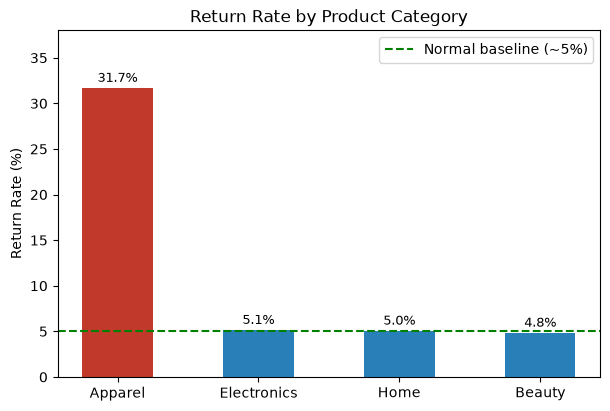

In [3]:
# Apparel in red, everything else in blue
colors = []
for category in df_rates['product_category']:
    if category == 'Apparel':
        colors.append('#c0392b')
    else:
        colors.append('#2980b9')

plt.figure(figsize=(7, 4.5))
plt.bar(df_rates['product_category'], df_rates['return_rate_pct'], color=colors, width=0.5)
plt.axhline(y=5, color='green', linestyle='--', label='Normal baseline (~5%)')

for i, rate in enumerate(df_rates['return_rate_pct']):
    plt.text(i, rate + 0.7, f'{rate:.1f}%', ha='center', fontsize=9)

plt.title('Return Rate by Product Category')
plt.ylabel('Return Rate (%)')
plt.ylim(0, 38)
plt.legend()
plt.show()

## 3. Total Refunds by Category

Checking how total refund amounts are distributed across categories:

In [4]:
refund_query = '''
SELECT
    product_category,
    COUNT(*) AS returns,
    ROUND(SUM(refund_amount), 2) AS total_refund,
    ROUND(SUM(refund_amount) * 100.0
          / (SELECT SUM(refund_amount) FROM transactions WHERE event_type = 'return'), 2) AS share_of_refunds_pct
FROM transactions
WHERE event_type = 'return'
GROUP BY product_category
ORDER BY total_refund DESC
'''

df_refunds = pd.read_sql_query(refund_query, conn)
df_refunds

,product_category,returns,total_refund,share_of_refunds_pct
0,Apparel,601,1663322.39,66.68
1,Home,100,284873.42,11.42
2,Electronics,105,283650.42,11.37
3,Beauty,99,262517.53,10.52


## 4. Why Are Items Returned?

Return reasons in each category. Every Apparel return is a size issue:

In [5]:
reason_query = '''
SELECT product_category, reason, COUNT(*) AS returns
FROM transactions
WHERE event_type = 'return'
GROUP BY product_category, reason
ORDER BY product_category, returns DESC
'''

pd.read_sql_query(reason_query, conn)

,product_category,reason,returns
0,Apparel,Size Issue,601
1,Beauty,Changed Mind,51
2,Beauty,Defective,48
3,Electronics,Defective,56
4,Electronics,Changed Mind,49
5,Home,Defective,52
6,Home,Changed Mind,48


## 5. Cost Savings Analysis

Estimating potential cost savings if we reduce Apparel return rates by improving size guides:

In [6]:
from cost_analysis import calculate_savings

savings_df = calculate_savings()
savings_df

Apparel orders:  1898
Apparel returns: 601 (31.7%)
Current cost of returns: Rs. 17.84 lakh

         Target  Projected Returns  Cost (Lakhs)  Savings (Lakhs)
20% return rate                379         11.25             6.59
10% return rate                189          5.61            12.23
 5% return rate                 94          2.79            15.05


,Target,Projected Returns,Cost (Lakhs),Savings (Lakhs)
0,20% return rate,379,11.25,6.59
1,10% return rate,189,5.61,12.23
2,5% return rate,94,2.79,15.05


In [7]:
conn.close()